# DADA2: 03 — The agent

Four TODOs.

Notebook 02 ended with a table and no winner. The filter wins on questions
that name a filing and loses on questions that compare. Hybrid is the other way round. We'll enable our agent to choose from these strategieis.

At the core, a decision model looks at the question and determines which kind it is, which then picks the first search. The same model looks at what came
back and says whether it is enough, and if not, why not. Every reason has one place to go. 

In essence, the decision model will make the decisions, while the chat model will only write a plan when one is needed and the answer.

![architecture](figures/architecture.png)

In [1]:
from dotenv import load_dotenv
load_dotenv()

from rag import config, decide, evaluate, retrieval

## 1. A model that picks instead of writes

Every model call you have made in this course returns text. When you wanted a
decision out of it, you asked for structured output and read a field. That
works, and it costs a chat call and a parse each time.

A decision model is built for the decision alone. You hand it some state and a
question with a fixed set of answers, and it returns a probability for each
one. No prose. It runs in well under a second, and it does not touch your
Gemini quota.

Cloudflare hosts one called `clef-flash`. `rag/decide.py` wraps it, and it is
given. Try it.

In [3]:
# study rag/decide.py to better understand how the API call is made to the decision model
answers = decide.decide(
    state="Checkout has been failing for every customer for the last hour.",
    questions={
        "urgent": {"type": "noul", "instructions": "Is this support request urgent?"},
        "team": {"type": "choice", "instructions": "Which team should handle it?",
                 "criteria": {"billing": "payments, invoices, refunds",
                              "technical": "outages, errors, configuration",
                              "sales": "plans and upgrades"}},
    })

print(answers["urgent"])
print(answers["team"])

{'type': 'noul', 'noul': 0.9529}
{'type': 'choice', 'choice': 'technical', 'probabilities': {'billing': 0.0427, 'technical': 0.9457, 'sales': 0.0116}, 'confidence': 0.8444}


`noul` is a yes-or-no, and you get the probability of yes. `choice` is a
pick from a list, and you get the pick plus a probability for every option.

That second thing is what a chat model with structured output does not give
you. A chat model says `technical`. This says `technical, 0.86`, and the 0.86
is something your code can act on.

## 2. Which kind of question is this?

Three kinds show up in our question sets, and notebook 02 measured which
search each one needs.

| kind | example | start with |
|---|---|---|
| specific | names one company and one year | `filter` |
| comparative | several companies, or years, or no company at all | `hybrid+rrf` |
| figure | asks for a number | the financials file, no search |

`decide.scope` asks the decision model which one. Watch the probabilities.

In [4]:
for q in ["What does NVIDIA say about export controls in its fiscal 2026 risk factors?",
          "How do AMD and NVIDIA describe their dependence on TSMC?",
          "What did Micron spend on research and development in fiscal 2025?",
          "Is anyone worried about China?"]:
    choice, probs = decide.scope(q)
    spread = "  ".join(f"{k} {v:.2f}" for k, v in probs.items())
    print(f"{choice:12} {spread}")
    print(f"             {q}\n")

specific     specific 0.95  comparative 0.03  figure 0.02
             What does NVIDIA say about export controls in its fiscal 2026 risk factors?

comparative  specific 0.06  comparative 0.92  figure 0.03
             How do AMD and NVIDIA describe their dependence on TSMC?

figure       specific 0.36  comparative 0.01  figure 0.63
             What did Micron spend on research and development in fiscal 2025?

comparative  specific 0.17  comparative 0.71  figure 0.12
             Is anyone worried about China?



Some of those are confident and some are not. On the 24 labeled questions in
`eval/`, this model gets about 20 right, and a Gemini structured-output call
gets about 21. They are not far apart, and the chat model is not slower.
What the decision model gives you is the number next to the answer, and a
call that costs nothing against the daily limit. Notebook 04 measures both.

### TODO 3.1 — route (1 pt)

`rag/agent.py`: `route` and `after_route`.

`route` calls `decide.scope` and turns the answer into a strategy name using
`START_WITH`. If the top probability is under `SURE`, the model is guessing,
so use `DEFAULT` instead. Count the call: `decision_calls` is 1.

`after_route` sends figure questions to `lookup` and everything else to
`retrieve`.

**Steps:**

1. `route(state)`: `scope, probs = decide.scope(state["question"])`. If `probs[scope] >= SURE`, the strategy is `START_WITH[scope]`; otherwise `DEFAULT`. Return `{"scope": ..., "strategy": ..., "decision_calls": 1}`.
2. `after_route(state)`: `"lookup"` if `state["scope"] == "figure"`, else `"retrieve"`.


In [5]:
from typing import Literal
from rag.agent import RetrievalState, START_WITH, DEFAULT, SURE

# TODO 3.1
def route(state: RetrievalState) -> dict:
    # your code here
    returnDict={}
    scope, probs=decide.scope(state["question"])
    returnDict["scope"]=scope
    if probs[scope]>=SURE:
        returnDict["strategy"]=START_WITH[scope]
    else:
        returnDict["strategy"]=DEFAULT
    returnDict["decision_calls"]=1
    return returnDict

def after_route(state: RetrievalState) -> Literal["lookup", "retrieve"]:
    # your code here
    if state["scope"]=="figure":
        return "lookup"
    return "retrieve"

for q in ["What does NVIDIA say about export controls in fiscal 2026?",
          "Is anyone worried about China?"]:
    out = route({"question": q})
    print(f"{out['scope']:12} -> {out['strategy']:18} then {after_route(out)}")

specific     -> filter             then retrieve
comparative  -> hybrid+rrf         then retrieve


## 3. Numbers are not in the prose

When we ask what Micron spent on R&D in fiscal 2025, every strategy in notebook 02
performs badly. The number is in a table, the table was chunked to confetti, and the words around it are the same in every year's filing. The same figure is
in `corpus/financials/` as structured data, where a number is a number.

In [6]:
from rag.agent import financial_fact

print(financial_fact("MU", "ResearchAndDevelopmentExpense"))
print()
print(financial_fact("AMD", "Nonsense")[:160])

MU ResearchAndDevelopmentExpense:
  period ending 2021-09-02: 2,663,000,000
  period ending 2022-09-01: 3,116,000,000
  period ending 2023-08-31: 3,114,000,000
  period ending 2024-08-29: 3,430,000,000
  period ending 2025-08-28: 3,798,000,000
  period ending 2026-09-03: 5,650,000,000

AMD has no concept named Nonsense. Available: GrossProfit, NetIncomeLoss, OperatingIncomeLoss, ResearchAndDevelopmentExpense, RevenueFromContractWithCustomerExc


### TODO 3.2 — lookup (1 pt)

`rag/agent.py`: `lookup`.

One chat call to name the figure (`Fact` is given), then `financial_fact`.
Return the table as the one document, with `verdict` already `sufficient` so
the graph goes straight to `answer`. 

`financial_fact` is given, and read what
it returns when the concept is wrong: a sentence listing what it does have.
- A tool that returns a helpful string gets a second try. 
- A tool that raises takes the graph down.

**Steps:**

1. Create a `namer` model with the structured output using `Fact` = config.chat().with_structured_output(Fact)`, then use `fact = retry(namer.invoke, "Which reported figure does this ask for? " + state["question"])`.
2. `table = financial_fact(fact.ticker, fact.concept)`.
3. Return the table as the one document: 

`{"documents": [(f"{fact.ticker}_financials.json", table)], "verdict": "sufficient", "attempts": 1, "chat_calls": 1}`.

The two numbers are not placeholders. `chat_calls` is a counter the graph adds up, and this node made exactly one chat call, the one that named the figure; the dictionary read after it is free. `attempts` is plain state that `decide_next` compares to the cap, and this path never reaches `decide_next`, so 1 just records that one attempt was made.


In [8]:
from rag.agent import Fact
from rag.util import retry

# TODO 3.2
def lookup(state: RetrievalState) -> dict:
    # your code here
    namer=config.chat().with_structured_output(Fact)
    fact=retry(namer.invoke, "Which reported figure does this ask for? "+state["question"])
    table=financial_fact(fact.ticker, fact.concept)
    return {"documents": [(f"{fact.ticker}_financials.json", table)], "verdict": "sufficient", "attempts": 1, "chat_calls": 1}


out = lookup({"question": "What did Micron spend on research and development in fiscal 2025?"})
print(out["documents"][0][1][:200])

MU ResearchAndDevelopmentExpense:
  period ending 2021-09-02: 2,663,000,000
  period ending 2022-09-01: 3,116,000,000
  period ending 2023-08-31: 3,114,000,000
  period ending 2024-08-29: 3,430,000,00


## 4. Enough, or why not?

In W06b the grader stopped saying `insufficient` and started saying why:
`absent`, `wrong_words`, or `incomplete`. Each one goes somewhere different.
Here the decision model does that job. `decide.diagnose` takes the question
and the passages and returns one of four verdicts, with probabilities.

In [9]:
q = "How do AMD and NVIDIA describe their dependence on TSMC?"
only_amd = retrieval.dense("dependence on TSMC", 5, where={"ticker": {"$eq": "AMD"}})

verdict, probs = decide.diagnose(q, only_amd)
print(verdict, {k: round(v, 2) for k, v in probs.items()})

/Users/sidharthayadav/Desktop/Agentic AI CS6983/agentic-ai-course/DADA2/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


incomplete {'sufficient': 0.27, 'absent': 0.15, 'wrong_words': 0.24, 'incomplete': 0.34}


In [10]:
q = "What is AMD's policy on employee dress code?"
verdict, probs = decide.diagnose(q, retrieval.STRATEGIES["filter"](q, 5))
print(verdict, {k: round(v, 2) for k, v in probs.items()})

absent {'sufficient': 0.03, 'absent': 0.9, 'wrong_words': 0.05, 'incomplete': 0.02}


Half the question answered is `incomplete`. A topic the filings do not cover
is `absent`. Look at the probability on `absent`. When it is high the model is
sure. When it is around 0.6 it is not, and we need to handle that case: 
a search that missed the rule looks the same as a rule that is not there. 

The
model cannot tell "I did not find it" from "it is not there" any better than
you could from the same passages. The probability is the one thing you have
that a yes-or-no grader would not have given you.

### TODO 3.3 — diagnose and decide (2 pts)

`rag/agent.py`: `diagnose` and `decide`.

`diagnose` calls `decide.diagnose` and stores the verdict and probabilities.
One rule: if the verdict is `absent` with a probability under `ABSENT_SURE`
and there are attempts left, call it `wrong_words` instead. One more search is
cheap, and a wrong `absent` is an answer that says "the filings do not cover
that" about something they do.

`decide` sends each verdict where it goes. `sufficient` and `absent` both go
to `answer`. `incomplete` goes to `plan`. `wrong_words` goes to `stronger`,
unless the strategy is already the strongest, in which case `answer`. The
attempt cap stops everything.

**Steps:**

`diagnose`, three steps:

1. Ask the decision model. `decide.diagnose` takes the question and the passages gathered so far and gives you back a verdict and the probabilities behind it.
2. Second-guess one verdict. If it said `absent` but was not sure of it (the probability is below `ABSENT_SURE`), and there are attempts left, treat it as `wrong_words` instead, so the graph searches once more before giving up.
3. Return the verdict and the probabilities, and count the call: this was one decision-model call.

`decide_next`, four checks, in this order, each one returning the name of the next node:

1. If the verdict is `sufficient` or `absent`, the search is over: go to `answer`.
2. If the attempt cap is reached, the search is over whatever the verdict was: `answer`.
3. If the verdict is `incomplete`, a part of the question has not been searched for yet: `plan`.
4. Otherwise the verdict is `wrong_words`. If there is a stronger search left (look the current strategy up in `STRONGER`), go to `stronger`; if there is not, `answer`.

The order matters. Putting the attempt cap first would stop a question the model has already answered.


In [14]:
from rag.agent import ABSENT_SURE, MAX_ATTEMPTS, STRONGER

# TODO 3.3
def diagnose(state: RetrievalState) -> dict:
    # your code here
    returnDict={}
    verdict, probs=decide.diagnose(state["question"], state["documents"])
    returnDict["verdict"]=verdict
    if verdict=="absent":
        if probs["absent"]<ABSENT_SURE:
            if state["attempts"]<MAX_ATTEMPTS:
                returnDict["verdict"]="wrong_words"
    returnDict["probabilities"]=probs
    returnDict["decision_calls"]=1
    return returnDict

def decide_next(state: RetrievalState) -> Literal["answer", "stronger", "plan"]:
    # your code here
    if state["verdict"] in ["sufficient","absent"]:
        return "answer"
    if state["attempts"]>=MAX_ATTEMPTS:
        return "answer"
    if state["verdict"]=="incomplete":
        return "plan"
    if state["verdict"]=="wrong_words":
        if state["strategy"] in STRONGER:
            return "stronger"
    return "answer"


state = {"question": q, "strategy": "filter", "attempts": 1,
         "documents": retrieval.STRATEGIES["filter"](q, 5)}
state.update(diagnose(state))
print(state["verdict"], "->", decide_next(state))

absent -> answer


## 5. Two ways to search again

`wrong_words` means the search was aimed at the right thing and missed. The
fix is the same search done harder: `STRONGER` says which strategy comes
next. `incomplete` means a part of the question has not been searched for at
all. The fix is a plan: the chat model writes the separate questions still
needed, each naming one company, and `execute` runs a filtered search for
each.

That is the whole difference from the ladder in W06b. The ladder climbed one
rung on every failure. This goes where the verdict points.

### TODO 3.4 — stronger, plan, execute, and the graph (2 pts)

`rag/agent.py`: `stronger`, `plan`, `execute`, `build_graph`.

`plan` is one chat call with `PLAN_PROMPT`, which wants to know what the
passages so far already cover, so the planner does not ask for it again.
`execute` runs `retrieval.with_filter` on each step and returns only the
passages you do not already have. `documents` has an add reducer.

`build_graph` is the diagram at the top. `after_route` and `decide` return
`Literal`s, which declare their edges.

**Steps:**

`stronger`, one line. Look the current strategy up in `STRONGER` and return
the next one as the new `strategy`. Nothing else in the state changes; the
graph goes back to `retrieve`, which reads the new name.

`plan`, three steps:

1. Make a planner: the chat model with structured output over `Plan`.
2. Tell it what is already covered, so it does not ask for it again. Take the
   sources of the documents in the state, sorted and joined with commas; if
   there are none, say `"nothing"`. Put that and the question into
   `PLAN_PROMPT`.
3. Call the planner through `retry` and return its `steps`, counting one chat
   call.

`execute`, three steps:

1. Note which documents the state already has, so you can skip them.
2. For each step in the plan, run `retrieval.with_filter(step, config.K)`.
   Each step names one company, which is what makes the filter work. Keep
   every hit you have not seen, and do not collect the same one twice.
3. Return the new documents (the reducer appends them), bump `attempts` by
   one, and count the chat calls: one per step, because each `with_filter`
   call extracts its own filter.

`build_graph`:

1. A `StateGraph` over `RetrievalState` with eight nodes, named after their
   functions: `route`, `lookup`, `retrieve`, `diagnose`, `stronger`, `plan`,
   `execute`, `answer`. Six of those you wrote above; `retrieve` and `answer`
   are given, so import them from `rag.agent`.
2. The edges are the arrows in the diagram. `START` goes to `route`. After
   `route`, a conditional edge on `after_route` picks `lookup` or `retrieve`.
   `lookup` goes straight to `answer`. `retrieve` goes to `diagnose`, and
   after `diagnose` a conditional edge on `decide_next` picks `answer`,
   `stronger` or `plan`. `stronger` goes back to `retrieve`. `plan` goes to
   `execute`, and `execute` goes back to `diagnose`. `answer` goes to `END`.
3. Compile and return it.

If the drawing shows an edge you did not add, one of the two `Literal`
annotations names a node that function never returns.


In [15]:
from rag.agent import Plan, PLAN_PROMPT

# TODO 3.4
def stronger(state: RetrievalState) -> dict:
    # your code here
    return {"strategy": STRONGER[state["strategy"]]}

def plan(state: RetrievalState) -> dict:
    # your code here
    planner=config.chat().with_structured_output(Plan)
    covered = ", ".join(sorted({source for source, _ in state["documents"]})) or "nothing"
    plan_prompt=PLAN_PROMPT.format(question=state["question"],covered=covered)
    out=retry(planner.invoke, plan_prompt)
    return {"steps": out.steps,"chat_calls":1}


def execute(state: RetrievalState) -> dict:
    # your code here
    findings=[]
    seen=set(state["documents"] or [])
    for step in state["steps"]:
        for hit in retrieval.with_filter(step, config.K):
            if hit not in seen:
                findings.append(hit)
                seen.add(hit)
    return {"documents":findings,"attempts":state["attempts"]+1, "chat_calls":len(state["steps"])}

This is the graph you are building, drawn by LangGraph from the reference
solution. Dotted lines are the two conditional edges, `after_route` and
`decide_next`; solid lines are fixed. When yours is wired, the drawing your
own `build_graph` produces in the next cell should match it.

![the retrieval graph](figures/graph.png)


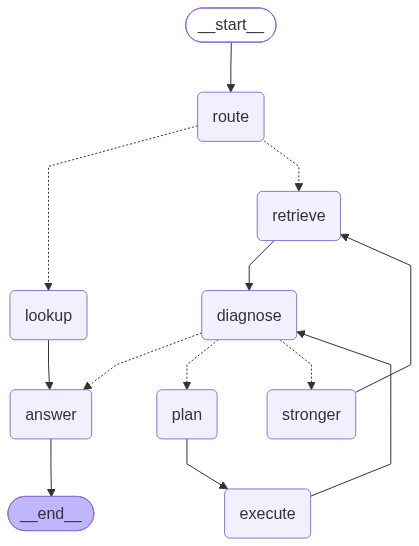

In [19]:
from rag.agent import answer, retrieve     # both given in the module
from langgraph.graph import StateGraph, START, END

# TODO 3.4
def build_graph():
    # your code here
    graph=StateGraph(RetrievalState)
    graph.add_node("retrieve",retrieve)
    graph.add_node("lookup",lookup)
    graph.add_node("answer",answer) 
    graph.add_node("diagnose",diagnose)
    graph.add_node("stronger",stronger)
    graph.add_node("plan",plan)
    graph.add_node("execute",execute)
    graph.add_node("route",route)
    graph.add_edge(START,"route")
    graph.add_conditional_edges("route",after_route)
    graph.add_edge("retrieve","diagnose")
    graph.add_conditional_edges("diagnose",decide_next)
    graph.add_edge("plan","execute")
    graph.add_edge("execute","diagnose")
    graph.add_edge("stronger","retrieve")
    graph.add_edge("lookup","answer")
    graph.add_edge("answer",END)
    return graph.compile()

graph = build_graph()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

Check the drawing against the figure at the top. An edge you did not intend
usually means a `Literal` lists a node the function never returns.

## 6. Four kinds of question, four paths

Run all four and watch which path each one takes, and what it cost.

In [20]:
def trace(question):
    print(question)
    for update in graph.stream({"question": question, "attempts": 0,
                                "chat_calls": 0, "decision_calls": 0},
                               stream_mode="updates"):
        for node, change in update.items():
            if node == "route":
                print(f"  route: {change['scope']} -> {change['strategy']}")
            elif node == "diagnose":
                p = change["probabilities"][change["verdict"]]
                print(f"  diagnose: {change['verdict']} ({p:.2f})")
            elif node == "plan":
                for step in change["steps"]:
                    print(f"  step: {step}")
            elif node in ("retrieve", "execute", "lookup"):
                print(f"  {node}: +{len(change['documents'])} (attempt {change['attempts']})")
            elif node == "stronger":
                print(f"  stronger: {change['strategy']}")
            elif node == "answer":
                print(f"  answer: {change['answer'][:90]}...")
    print()

for q in ["What does NVIDIA say about export controls in its fiscal 2026 risk factors?",
          "How do AMD and NVIDIA describe their dependence on TSMC?",
          "What did Micron spend on research and development in fiscal 2025?",
          "What is AMD's policy on employee dress code?"]:
    trace(q)

What does NVIDIA say about export controls in its fiscal 2026 risk factors?
  route: specific -> filter
  retrieve: +5 (attempt 1)
  diagnose: sufficient (0.69)
  answer: Based on the provided passages, NVIDIA states the following about export controls in its f...

How do AMD and NVIDIA describe their dependence on TSMC?
  route: comparative -> hybrid+rrf
  retrieve: +5 (attempt 1)
  diagnose: sufficient (0.35)
  answer: Based on the provided passages, the supplied SEC filings do not cover NVIDIA's dependence ...

What did Micron spend on research and development in fiscal 2025?
  route: figure -> filter
  lookup: +1 (attempt 1)
  answer: Micron spent $3,798,000,000 on research and development in fiscal 2025 [MU_financials.json...

What is AMD's policy on employee dress code?
  route: specific -> filter
  retrieve: +5 (attempt 1)
  diagnose: absent (0.90)
  answer: The filings in this corpus do not cover that....



The first is one search and done. The second comes back `incomplete`, gets a
plan, and finishes on the second pass. The third never searches. The fourth
stops after one search with `absent`.

Now the same four through `rag/ladder.py`, the agent from the first version of
this assignment. It has no decision model and climbs one rung per failure.

In [21]:
from rag import ladder

for q in ["How do AMD and NVIDIA describe their dependence on TSMC?",
          "What is AMD's policy on employee dress code?"]:
    s = ladder.run(q)
    print(f"ladder: rung {s['rung']}, {s['attempts']} attempts, {s['chat_calls']} chat calls")
    print(f"  {s['answer'][:120]}...\n")

ladder: rung 2, 3 attempts, 9 chat calls
  Based on the provided SEC filings, AMD and NVIDIA describe their dependence on TSMC as follows:

* **AMD** states that i...

ladder: rung 2, 3 attempts, 9 chat calls
  Based on the provided passages, there is no information regarding AMD's policy on employee dress code....



Compare the chat-call counts with yours. The ladder spends them climbing. The
dress-code question is the one to look at: the ladder tries all three rungs
to learn what the first one knew.

## 7. Deploy it

`app.py` serves your agent through `agentui.py`, the same Gradio UI as DADA1. The agent is `build_agent()` at the bottom of `rag/agent.py`. It imports from `rag/`, so it works once your modules do. 

Test it locally:

```bash
python app.py        # http://localhost:7860
```

Then put it on Render. Remember that your deployment needs only the app version, not the notebooks. `DEPLOY.md` has the steps.

The app never indexes, as you should have created your index on Pinecone while working through the Notebooks. It embeds each question the way the index was built
and searches. `EMBEDDINGS=cloudflare` on Render is the same setting as here, and it also serves an index built with the Ollama backup, since the two make the same vectors. 

Try it before you push: run the app locally with the Render settings and ask a question. If it works here it works there.

Then ask the deployed app a question the corpus cannot answer, and see what it does with it.

## Before you move on

Move your answers into `rag/agent.py`. Notebook 04 and `app.py` import from
the module.

In [24]:
import importlib
from rag import agent
importlib.reload(agent)

s = agent.run("How do AMD and NVIDIA describe their dependence on TSMC?")
print(f"{s['scope']} -> {s['strategy']}, verdict {s['verdict']}, "
      f"{s['chat_calls']} chat + {s['decision_calls']} decision calls")
assert isinstance(s["answer"], str) and s["answer"]
print("module works")

comparative -> hybrid+rrf, verdict sufficient, 2 chat + 2 decision calls
module works
